## peformance of models

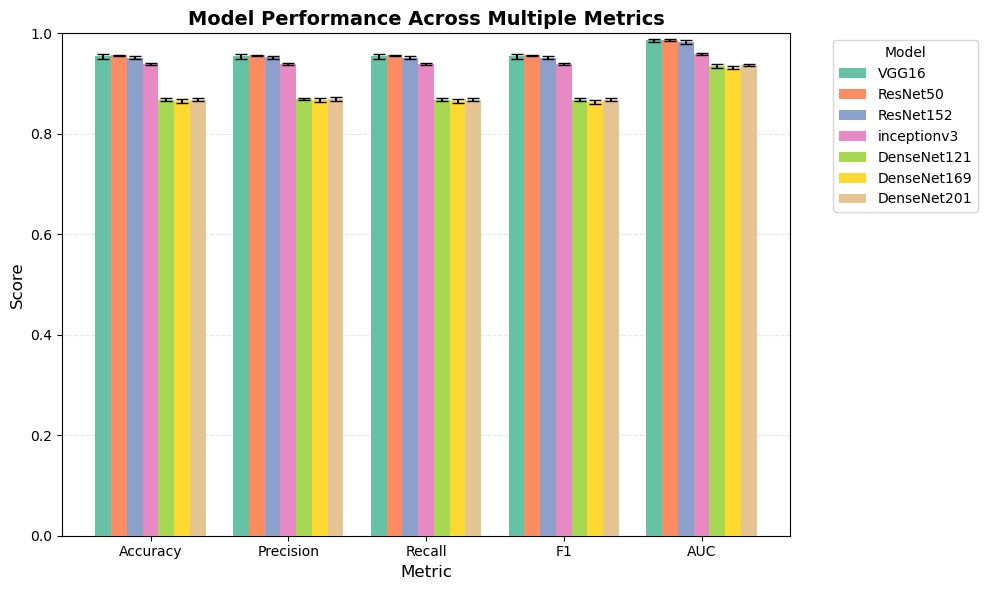

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],

    "VGG16_mean": [0.9542, 0.9543, 0.9542, 0.9542, 0.9860],
    "VGG16_std":  [0.0046, 0.0045, 0.0046, 0.0046, 0.0027],

    "ResNet50_mean": [0.9561, 0.9561, 0.9561, 0.9561, 0.9867],
    "ResNet50_std":  [0.0017, 0.0017, 0.0017, 0.0017, 0.0022],

    "ResNet152_mean": [0.9518, 0.9520, 0.9518, 0.9518, 0.9826],
    "ResNet152_std":  [0.0027, 0.0026, 0.0027, 0.0027, 0.0033],

    "inceptionv3_mean": [0.9393, 0.9394, 0.9393, 0.9393, 0.9593],
    "inceptionv3_std":  [0.0024, 0.0023, 0.0024, 0.0024, 0.0023],

    "DenseNet121_mean": [0.8678, 0.8692, 0.8677, 0.8676, 0.9348],
    "DenseNet121_std":  [0.0028, 0.0019, 0.0028, 0.0029, 0.0032],

    "DenseNet169_mean": [0.8644, 0.8665, 0.8644, 0.8642, 0.9317],
    "DenseNet169_std":  [0.0039, 0.0038, 0.0039, 0.0039, 0.0035],
    
    "DenseNet201_mean": [0.8679, 0.8696, 0.8679, 0.8677, 0.9365],
    "DenseNet201_std":  [0.0033, 0.0045, 0.0034, 0.0033, 0.0015]
}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "ResNet50", "ResNet152", "inceptionv3", "DenseNet121", "DenseNet169", "DenseNet201"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

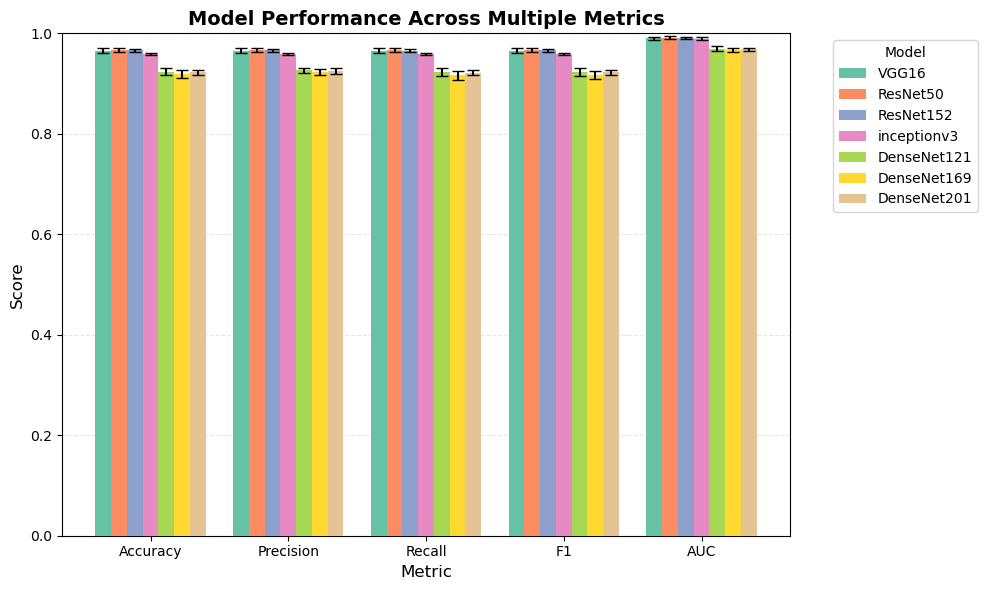

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],

    "VGG16_mean": [0.9656, 0.9655, 0.9655, 0.9655, 0.9901],
    "VGG16_std":  [0.0052, 0.0051, 0.0052, 0.0052, 0.0029],

    "ResNet50_mean": [0.9668, 0.9670, 0.9665, 0.9667, 0.9914],
    "ResNet50_std":  [0.0040, 0.0040, 0.0040, 0.0040, 0.0023],

    "ResNet152_mean": [0.9662, 0.9664, 0.9658, 0.9661, 0.9911],
    "ResNet152_std":  [0.0027, 0.0026, 0.0027, 0.0027, 0.0023],

    "inceptionv3_mean": [0.9593, 0.9596, 0.9589, 0.9592, 0.9888],
    "inceptionv3_std":  [0.0023, 0.0020, 0.0025, 0.0023, 0.0030],

    "DenseNet121_mean": [0.9238, 0.9263, 0.9222, 0.9233, 0.9697],
    "DenseNet121_std":  [0.0073, 0.0055, 0.0080, 0.0075, 0.0041],

    "DenseNet169_mean": [0.9186, 0.9228, 0.9164, 0.9179, 0.9673],
    "DenseNet169_std":  [0.0079, 0.0066, 0.0084, 0.0081, 0.0041],
    
    "DenseNet201_mean": [0.9228, 0.9248, 0.9216, 0.9224, 0.9685],
    "DenseNet201_std":  [0.0049, 0.0056, 0.0049, 0.0049, 0.0032]
}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "ResNet50", "ResNet152", "inceptionv3", "DenseNet121", "DenseNet169", "DenseNet201"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

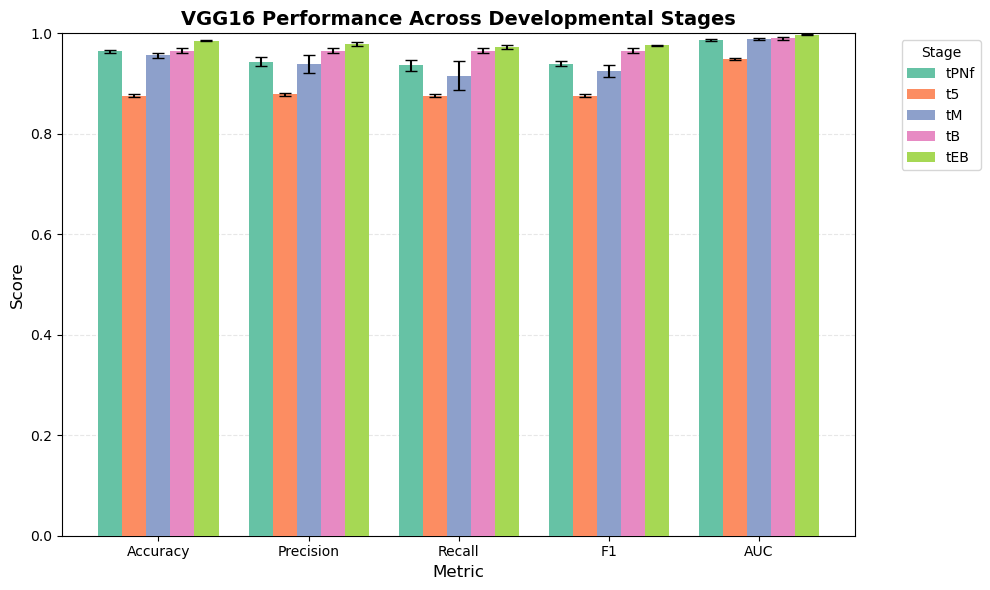

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ================================
# 你的数据（把 mean/std 换成你的）
# ================================
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],

    "tPNf_mean": [0.9150, 0.9156, 0.9150, 0.9150, 0.9711],
    "tPNf_std":  [0.0057, 0.0053, 0.0057, 0.0057, 0.0029],

    "t5_mean":   [0.9141, 0.9163, 0.9140, 0.9139, 0.9707],
    "t5_std":    [0.0080, 0.0068, 0.0081, 0.0082, 0.0027],

    "tM_mean":   [0.9564, 0.9391, 0.9159, 0.9249, 0.9885],
    "tM_std":    [0.0054, 0.0184, 0.0296, 0.0122, 0.0017],

    "tB_mean":   [0.9656, 0.9655, 0.9655, 0.9655, 0.9901],
    "tB_std":    [0.0052, 0.0051, 0.0052, 0.0052, 0.0029],

    "tEB_mean":  [0.9852, 0.9793, 0.9726, 0.9759, 0.9973],
    "tEB_std":   [0.0007, 0.0043, 0.0035, 0.0011, 0.0004]
}

df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
stage_order  = ["tPNf", "t5", "tM", "tB", "tEB"]

df = df.set_index("Metric").loc[metric_order]

# ================================
# 开始画图：每个 metric 一组，每组多个 stage
# ================================
x = np.arange(len(metric_order))
group_width = 0.8
bar_width   = group_width / len(stage_order)

palette = sns.color_palette("Set2", n_colors=len(stage_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, stage in enumerate(stage_order):
    mean_vals = df[f"{stage}_mean"].values
    std_vals  = df[f"{stage}_std"].values

    # 每个发育时期在一组中的相对位置
    pos = x - group_width/2 + bar_width/2 + j * bar_width

    # error bar（限制在 0~1 范围）
    upper = np.minimum(1.0, mean_vals + std_vals) - mean_vals
    lower = mean_vals - np.maximum(0.0, mean_vals - std_vals)
    yerr  = np.vstack([lower, upper])

    ax.bar(pos, mean_vals,
           width=bar_width,
           label=stage,
           color=palette[j],
           edgecolor="none",
           yerr=yerr,
           capsize=4,
           zorder=3)

# 样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("VGG16 Performance Across Developmental Stages",
             fontsize=14, weight="bold")

ax.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)

plt.tight_layout()
plt.show()

## 妊娠情况

In [5]:
import pandas as pd

# 读取 Excel 文件
df_2023 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2023-冷冻.xls")
df_2024 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2024-冷冻.xls")
df_2025 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2025-冷冻.xls")

df_all = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)

keep_cols = [
    "女病人ID",
    "ARTID",
    "年龄",
    "Bmi(新鲜周期)",
    "移植胚胎存活细胞数1",
    "移植胚胎存活细胞数2",
    "移植数",
    "妊娠结局", 
    "胎儿数"
]

df_selected = df_all[[col for col in keep_cols if col in df_all.columns]]

# === 步骤 1: 仅保留 移植胚胎存活细胞数1 > 20 的行 ===
df_selected.loc[:, "移植胚胎存活细胞数1"] = (
    pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce")
    .astype("Int64")
)
df_selected = df_selected[pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce") > 20]

# === 步骤 2: 将 移植胚胎存活细胞数1 转为字符型 ===
df_selected["移植胚胎存活细胞数1"] = df_selected["移植胚胎存活细胞数1"].astype(str)

# === 步骤 3: 保留 胎儿数 == 0 或 胎儿数 == 移植数 的行 ===
df_selected["胎儿数"] = pd.to_numeric(df_selected["胎儿数"], errors="coerce")
df_selected["移植数"] = pd.to_numeric(df_selected["移植数"], errors="coerce")

df_filtered = df_selected[
    (df_selected["胎儿数"] == 0) |
    (df_selected["胎儿数"] == df_selected["移植数"])
].copy()

df_filtered = df_filtered.dropna(subset=["妊娠结局"]).copy()
# === 输出结果 ===
print(df_filtered.shape)
print(df_filtered.head)

(2747, 9)
<bound method NDFrame.head of        女病人ID   ARTID    年龄  Bmi(新鲜周期) 移植胚胎存活细胞数1  移植胚胎存活细胞数2  移植数  妊娠结局  胎儿数
1     138598  247840  31.5      36.21        411         NaN    1  临床妊娠    0
2     138598  268488  31.9      36.21        421         NaN    1  临床妊娠    1
3     285001  255700  25.8      36.05        411         NaN    1  临床妊娠    1
5     278932  247102  26.8      34.85        421         NaN    1  临床妊娠    1
6     263319  225820  33.6      33.50        423         NaN    1  临床妊娠    1
...      ...     ...   ...        ...        ...         ...  ...   ...  ...
3688  234340  369002  35.3      19.53        412         NaN    1   未妊娠    0
3691  305431  369547  30.6      18.29        422         NaN    1  生化妊娠    0
3699  289487  370440  36.5      24.09        411         NaN    1  生化妊娠    0
3703  296780  371221  39.8      23.44        323         NaN    1   未妊娠    0
3706  318372  371961  28.9      18.37        411         NaN    1   未妊娠    0

[2747 rows x 9 columns]>


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/529606114.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '<IntegerArray>
[  7, 411, 421, 411,  12, 421, 423, 421, 412, 411,
 ...
 412, 323, 411, 411,   7, 323, 312, 323, 423, 411]
Length: 3723, dtype: Int64' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_selected.loc[:, "移植胚胎存活细胞数1"] = (


In [6]:
import pandas as pd

# 确保类型正确
df_filtered["移植胚胎存活细胞数1"] = df_filtered["移植胚胎存活细胞数1"].astype(str)
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)
df_filtered = df_filtered[df_filtered["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# 统计每种胚胎质量的妊娠情况
preg_stats = (
    df_filtered
    .groupby("移植胚胎存活细胞数1")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)

# 计算妊娠率（百分比）
preg_stats["妊娠概率"] = preg_stats["临床妊娠数"] / preg_stats["总数"] * 100

# 排序（从高到低）
preg_stats = preg_stats.sort_values("妊娠概率", ascending=False)

# 定义转换函数
def convert_to_grade(code):
    code = str(code)
    if len(code) != 3:
        return None
    mapping = {"1": "A", "2": "B", "3": "C"}
    first = code[0]
    second = mapping.get(code[1], "?")
    third = mapping.get(code[2], "?")
    return f"{first}{second}{third}"

# 在 preg_stats 上添加囊胚等级列
preg_stats["囊胚等级"] = preg_stats["移植胚胎存活细胞数1"].apply(convert_to_grade)
preg_stats["Expansion"] = preg_stats["囊胚等级"].str[0]
preg_stats["ICM"] = preg_stats["囊胚等级"].str[1]
preg_stats["TE"] = preg_stats["囊胚等级"].str[2]

# 重新排列列顺序
preg_stats = preg_stats[
    ["囊胚等级", "Expansion", "ICM", "TE", "总数", "临床妊娠数", "妊娠概率"]
]

# 输出结果
print("各胚胎质量对应妊娠概率：")
print(preg_stats)

各胚胎质量对应妊娠概率：
   囊胚等级 Expansion ICM TE   总数  临床妊娠数        妊娠概率
17  5BA         5   B  A    1      1  100.000000
15  5AA         5   A  A   12     12  100.000000
18  5BB         5   B  B    5      4   80.000000
4   3BA         3   B  A    4      3   75.000000
7   4AA         4   A  A  990    713   72.020202
10  4BA         4   B  A  105     74   70.476190
21  6AA         6   A  A   13      9   69.230769
24  6BA         6   B  A    3      2   66.666667
8   4AB         4   A  B  425    279   65.647059
1   3AA         3   A  A   17     11   64.705882
2   3AB         3   A  B   55     31   56.363636
9   4AC         4   A  C   32     18   56.250000
11  4BB         4   B  B  315    177   56.190476
16  5AB         5   A  B    4      2   50.000000
19  5BC         5   B  C    4      2   50.000000
5   3BB         3   B  B  140     62   44.285714
12  4BC         4   B  C  398    172   43.216080
25  6BB         6   B  B    7      3   42.857143
6   3BC         3   B  C  191     72   37.696335
26  6BC

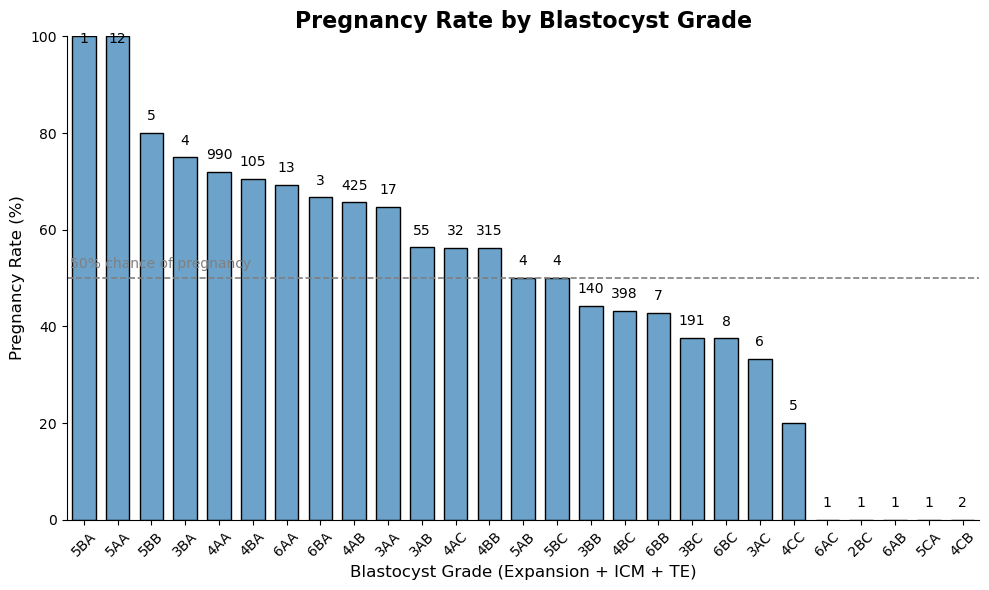

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))

bar_color = "#5DA5DA"  # 清爽蓝，可换成别的十六进制颜色

sns.barplot(
    data=preg_stats,
    x="囊胚等级",
    y="妊娠概率",
    color=bar_color,
    edgecolor="black",
    width=0.7,
    ax=ax
)

# --- Titles and labels (English) ---
ax.set_title("Pregnancy Rate by Blastocyst Grade", fontsize=16, fontweight="bold")
ax.set_xlabel("Blastocyst Grade (Expansion + ICM + TE)", fontsize=12)
ax.set_ylabel("Pregnancy Rate (%)", fontsize=12)

# --- Add a 50% reference line ---
ax.set_ylim(0, 100)
ax.axhline(50, linestyle="--", linewidth=1.2, color="gray")
ax.text(
    x=-0.4, y=52, s="50% chance of pregnancy", color="gray",
    fontsize=10
)

categories = [t.get_text() for t in ax.get_xticklabels()]
counts = (
    preg_stats.set_index("囊胚等级")
              .reindex(categories)["总数"]
              .fillna(0).astype(int)
    .tolist()
)

for patch, n in zip(ax.patches, counts):
    x = patch.get_x() + patch.get_width() / 2.0   # 柱子中心
    y = patch.get_height()                        # 柱子高度（=妊娠率）
    y_label = min(y + 2, 98)                      # 往上抬一点，且不超出顶部
    ax.text(x, y_label, n, ha="center", va="bottom",
            fontsize=10, color="black")
# --- Style ---
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

✅ 各质量类别妊娠成功率：
        Quality  Total  Pregnant  Pregnancy Rate (%)
1  Good-quality   1630      1137           69.754601
0  Fair-quality    460       243           52.826087
2  Poor-quality    656       273           41.615854


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/668641144.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


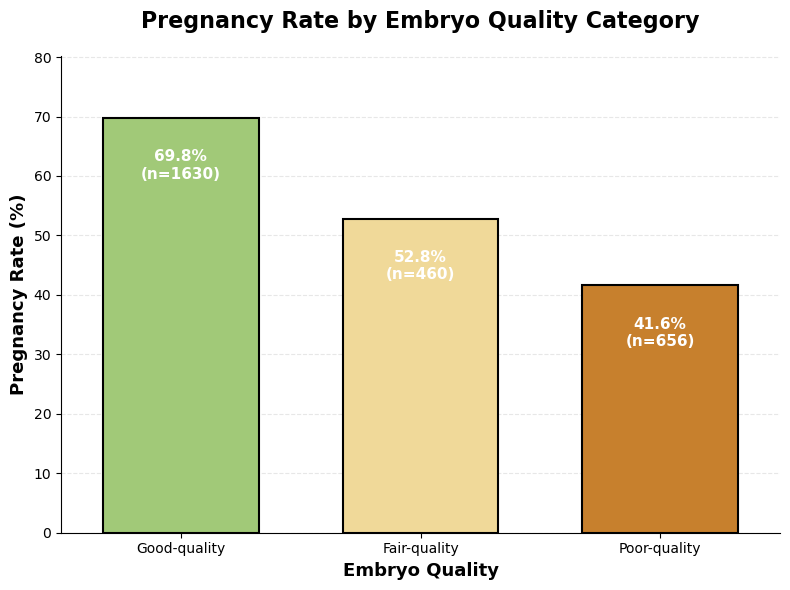

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 假设已有 preg_stats，包含列 ["囊胚等级", "总数", "临床妊娠数", "妊娠概率"]

# -------------------------------
# 1️⃣ 分类函数
# -------------------------------
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]

    # Fair-quality (exact matches)
    if grade in ["3BB","4BB", "5BB"]:
        return "Fair-quality"
    # Good-quality: extension ≥3 and (AA or AB or BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

# -------------------------------
# 2️⃣ 添加分类列
# -------------------------------
preg_stats["Quality"] = preg_stats["囊胚等级"].apply(classify_quality)

# -------------------------------
# 3️⃣ 按 Quality 统计妊娠率
# -------------------------------
quality_stats = (
    preg_stats
    .groupby("Quality")
    .agg(
        Total=("总数", "sum"),
        Pregnant=("临床妊娠数", "sum")
    )
    .reset_index()
)
quality_stats["Pregnancy Rate (%)"] = quality_stats["Pregnant"] / quality_stats["Total"] * 100

# 🔥 定义质量顺序（从好到差）
quality_order = ["Good-quality", "Fair-quality", "Poor-quality"]
quality_stats["Quality"] = pd.Categorical(
    quality_stats["Quality"],
    categories=quality_order,
    ordered=True
)
quality_stats = quality_stats.sort_values("Quality")

print("✅ 各质量类别妊娠成功率：")
print(quality_stats)

# -------------------------------
# 4️⃣ 绘图
# -------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# 🎨 配色：绿色(Good) → 黄色(Fair) → 橙色(Poor)
palette = ["#A1D76A", "#FEE08B", "#E08214"] 

sns.barplot(
    data=quality_stats,
    x="Quality",
    y="Pregnancy Rate (%)",
    palette=palette,
    edgecolor="black",
    linewidth=1.5,
    width=0.65,
    ax=ax,
    order=quality_order  # 🔥 强制顺序
)

# 🏷️ 添加数值标签（优化位置）
for i, row in quality_stats.iterrows():
    rate = row["Pregnancy Rate (%)"]
    total = int(row["Total"])

    # 📍 标签位置自适应：柱子高时放内部，低时放外部
    if rate > 15:
        y_pos = rate - 8  # 放在柱子内部
        color = "white"
        weight = "bold"
    else:
        y_pos = rate + 3  # 放在柱子上方
        color = "black"
        weight = "normal"

    ax.text(
        quality_order.index(row["Quality"]),  # x位置
        y_pos,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        va="center" if rate > 15 else "bottom",
        fontsize=11,
        color=color,
        weight=weight
    )

# -------------------------------
# 5️⃣ 美化
# -------------------------------
ax.set_title("Pregnancy Rate by Embryo Quality Category",
             fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("Embryo Quality", fontsize=13, fontweight="bold")
ax.set_ylabel("Pregnancy Rate (%)", fontsize=13, fontweight="bold")
ax.set_ylim(0, max(quality_stats["Pregnancy Rate (%)"]) * 1.15)  # 动态上限

# 🎯 网格线（仅横向）
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ===============================
# 1️⃣ 数据预处理
# ===============================
# 确保类型正确
df_filtered["移植胚胎存活细胞数1"] = df_filtered["移植胚胎存活细胞数1"].astype(str)
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)

# 仅保留长度≥3的编码（如 411、422 等）
df_filtered = df_filtered[df_filtered["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# ===============================
# 2️⃣ 数字编码 → 囊胚等级（4AA 等）
# ===============================
def convert_to_grade(code):
    code = str(code)
    if len(code) != 3:
        return None
    mapping = {"1": "A", "2": "B", "3": "C"}
    first = code[0]         # 扩张度
    second = mapping.get(code[1], "?")  # ICM
    third = mapping.get(code[2], "?")   # TE
    return f"{first}{second}{third}"

df_filtered["囊胚等级"] = df_filtered["移植胚胎存活细胞数1"].apply(convert_to_grade)

# ===============================
# 3️⃣ 囊胚等级 → 质量分类
# ===============================
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]

    # Fair-quality（中等质量）
    if grade in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair-quality"
    # Good-quality：扩张度 ≥3 且 (AA / AB / BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

df_filtered["Quality"] = df_filtered["囊胚等级"].apply(classify_quality)

# ===============================
# 4️⃣ 保存完整表格（每条记录带 Quality）
# ===============================
df_filtered.to_csv("Embryo_FullStats_withQuality.csv", index=False, encoding="utf-8-sig")

## 年龄情况

✅ 各年龄段统计：
     年龄段    人数        百分比
0  18-24    91   2.091473
1  25-29   937  21.535279
2  30-34  1742  40.036773
3  35-39  1063  24.431165
4  40-44   455  10.457366
5    ≥45    63   1.447943


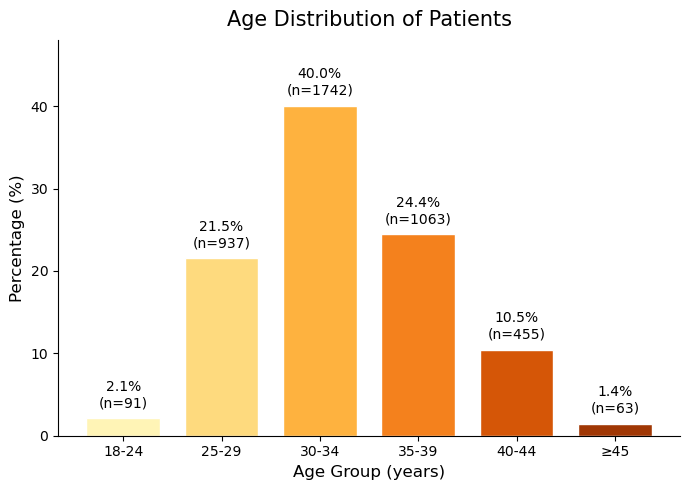

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 读取与清洗数据
# ==============================
df_age = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/SlidePatientBirthDates.csv")

df_age["Age"] = pd.to_numeric(df_age["Age"], errors="coerce")
df_age = df_age[df_age["Age"].notna() & (df_age["Age"] >= 18) & (df_age["Age"] <= 100)].copy()

# ==============================
# 2️⃣ 按年龄区间分组
# ==============================
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "≥45"]
df_age["年龄段"] = pd.cut(df_age["Age"], bins=bins, labels=labels, right=False)

# ==============================
# 3️⃣ 统计每个年龄段的数量与百分比
# ==============================
age_stats = (
    df_age["年龄段"]
    .value_counts()
    .sort_index()
    .reset_index()
)
age_stats.columns = ["年龄段", "人数"]
age_stats["百分比"] = age_stats["人数"] / age_stats["人数"].sum() * 100

print("✅ 各年龄段统计：")
print(age_stats)

# ==============================
# 4️⃣ 设置配色
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))

# ==============================
# 5️⃣ 绘图
# ==============================
plt.figure(figsize=(7, 5))
bars = plt.bar(
    age_stats["年龄段"],
    age_stats["百分比"],
    color=colors,
    edgecolor="white",
    width=0.75
)

# ==============================
# 6️⃣ 美化图形
# ==============================
plt.title("Age Distribution of Patients", fontsize=15, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.ylim(0, age_stats["百分比"].max() * 1.2)

# 添加百分比与人数标签
for i, row in age_stats.iterrows():
    plt.text(
        i, row["百分比"] + 1,
        f"{row['百分比']:.1f}%\n(n={row['人数']})",
        ha='center', va='bottom', fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/3958504813.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("年龄段")


✅ 各年龄段妊娠率：
     年龄段    总数  临床妊娠数     妊娠率(%)
0  18-24    73     51  69.863014
1  25-29   686    479  69.825073
2  30-34  1131    730  64.544651
3  35-39   625    333  53.280000
4  40-44   223     59  26.457399
5   >=45     8      1  12.500000


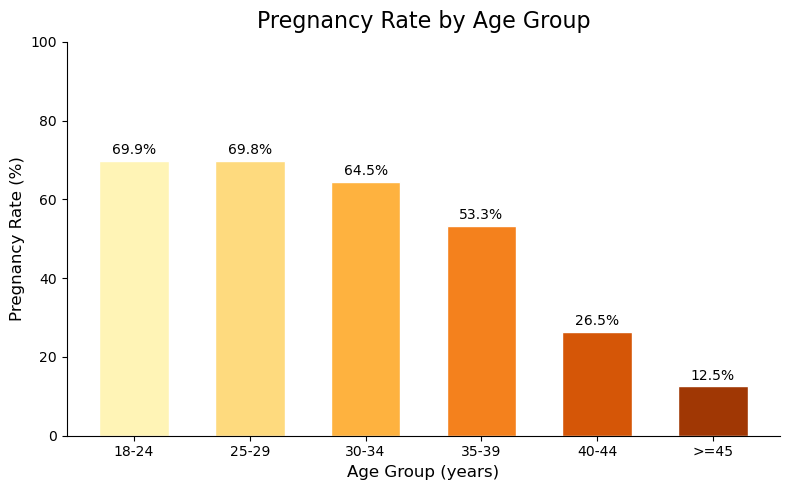

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 数据准备
# ==============================
df_filtered["年龄"] = pd.to_numeric(df_filtered["年龄"], errors="coerce")

# 年龄区间
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", ">=45"]
df_filtered["年龄段"] = pd.cut(df_filtered["年龄"], bins=bins, labels=labels, right=False)

# 各年龄段妊娠率
age_stats = (
    df_filtered
    .groupby("年龄段")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)
age_stats["妊娠率(%)"] = age_stats["临床妊娠数"] / age_stats["总数"] * 100

print("✅ 各年龄段妊娠率：")
print(age_stats)

# ==============================
# 2️⃣ 自定义渐变配色（黄色→橙色）
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))  # 黄色到橙棕色渐变
# 或者更亮：sns.color_palette("YlOrRd", n_colors=len(age_stats))

# ==============================
# 3️⃣ 绘图
# ==============================
plt.figure(figsize=(8, 5))

bars = plt.bar(
    age_stats["年龄段"],
    age_stats["妊娠率(%)"],
    color=colors,
    edgecolor="white",
    width=0.6
)

# ==============================
# 4️⃣ 美化
# ==============================
plt.title("Pregnancy Rate by Age Group", fontsize=16, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Pregnancy Rate (%)", fontsize=12)
plt.ylim(0, 100)

# 添加柱顶数值
for i, row in age_stats.iterrows():
    plt.text(i, row["妊娠率(%)"] + 1, f"{row['妊娠率(%)']:.1f}%", 
             ha='center', va='bottom', fontsize=10)

# 优化外观
sns.despine()
plt.tight_layout()
plt.show()

## CHAID

In [12]:
import pandas as pd
import numpy as np
import re
from CHAID import Tree

# ==============================
# 1️⃣ 数据加载与清洗
# ==============================
df = df_filtered.copy()

df["年龄"] = pd.to_numeric(df["年龄"], errors="coerce")
df["Bmi(新鲜周期)"] = pd.to_numeric(df["Bmi(新鲜周期)"], errors="coerce")

# 保留有效妊娠结局
df["Pregnancy"] = (df["妊娠结局"] == "临床妊娠").astype(int)

print(df.shape)

# ==============================
# 2️⃣ 胚胎编码规范化
# ==============================
def to_abc_grade(x):
    if pd.isna(x): return None
    s = str(x).strip().upper()
    s = re.sub(r'[^0-9A-Z]', '', s)
    if len(s) < 3 or not s[0].isdigit():
        return None
    exp = s[0]
    tail = s[1:]
    if len(tail) < 2:
        return None
    c2, c3 = tail[0], tail[1]
    d2l = {'1': 'A', '2': 'B', '3': 'C'}
    def norm_one(ch):
        if ch in d2l: return d2l[ch]
        if ch in ('A','B','C'): return ch
        return None
    icm, te = norm_one(c2), norm_one(c3)
    if icm is None or te is None:
        return None
    return f"{exp}{icm}{te}"

df["GradeABC"] = df["移植胚胎存活细胞数1"].apply(to_abc_grade)
df = df[df["GradeABC"].notna()].copy()

# ==============================
# 3️⃣ 按规则划分胚胎质量
# ==============================
FAIR_SET = {"3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"}

def classify_quality(grade_abc):
    exp, icm, te = grade_abc[0], grade_abc[1], grade_abc[2]
    if grade_abc in FAIR_SET:
        return "Fair-quality"
    if int(exp) >= 3 and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    return "Poor-quality"

df["Quality"] = df["GradeABC"].apply(classify_quality)
df = df[df["Quality"].isin(["Good-quality", "Poor-quality"])].copy()
df["Quality"] = df["Quality"].astype("category")

# ==============================
# 4️⃣ 年龄分组
# ==============================
bins = [-np.inf, 30, 32, 34, 36, 38, 40, np.inf]
labels = ["≤30", "31–32", "33–34", "35–36", "37–38", "39–40", "≥41"]
df["AgeGroup"] = pd.cut(df["年龄"], bins=bins, labels=labels, right=True)
df = df[df["AgeGroup"].notna()].copy()
df["AgeGroup"] = df["AgeGroup"].astype("category")

# ==============================
# 5️⃣ BMI 分组（根据 WHO 标准）
# ==============================
def bmi_group(bmi):
    if pd.isna(bmi):
        return None
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 24:
        return "Normal"
    elif bmi < 28:
        return "Overweight"
    else:
        return "Obese"

df["BMIgroup"] = df["Bmi(新鲜周期)"].apply(bmi_group)
df = df[df["BMIgroup"].notna()].copy()
df["BMIgroup"] = df["BMIgroup"].astype("category")

print("\n✅ 胚胎质量分布：")
print(df["Quality"].value_counts())
print("\n✅ 年龄组分布：")
print(df["AgeGroup"].value_counts())
print("\n✅ BMI 分布：")
print(df["BMIgroup"].value_counts())

# ==============================
# 6️⃣ 构建 CHAID 决策树
# ==============================
variables = {
    'AgeGroup': 'nominal',
    'Quality': 'nominal',
    'BMIgroup': 'nominal'
}

chaid_tree = Tree.from_pandas_df(
    df,
    variables,
    'Pregnancy',
    max_depth=5,
    min_child_node_size=20
)

# ==============================
# 7️⃣ 输出结果
# ==============================
print("\n📊 CHAID 决策树结构：")
chaid_tree.print_tree()

(2746, 13)

✅ 胚胎质量分布：
Quality
Good-quality    1610
Poor-quality     589
Name: count, dtype: int64

✅ 年龄组分布：
AgeGroup
≤30      657
31–32    407
33–34    341
35–36    336
37–38    190
≥41      144
39–40    124
Name: count, dtype: int64

✅ BMI 分布：
BMIgroup
Normal         1338
Overweight      479
Underweight     230
Obese           152
Name: count, dtype: int64

📊 CHAID 决策树结构：
([], {0: 825.0, 1: 1374.0}, (Quality, p=2.4788806412139664e-32, score=140.14157067916878, groups=[['Good-quality'], ['Poor-quality']]), dof=1))
|-- (['Good-quality'], {0: 485.0, 1: 1125.0}, (AgeGroup, p=7.275884608101298e-16, score=73.5871247089839, groups=[['31–32', '≤30'], ['33–34', '35–36'], ['37–38', '39–40'], ['≥41']]), dof=3))
|   |-- (['31–32', '≤30'], {0: 193.0, 1: 631.0}, <Invalid Chaid Split> - p-value greater than alpha merge)
|   |-- (['33–34', '35–36'], {0: 156.0, 1: 342.0}, <Invalid Chaid Split> - p-value greater than alpha merge)
|   |-- (['37–38', '39–40'], {0: 86.0, 1: 125.0}, <Invalid Chaid Split> -

/Users/lzz/anaconda3/lib/python3.11/site-packages/CHAID/graph.py:13: UserWarning: Imports of optional packages needed to generate graphs failed. Please install with the "graph" option.
  warnings.warn(UserWarning('Imports of optional packages needed to generate graphs failed. Please install with the "graph" option.'))


In [13]:
from graphviz import Digraph

# ========= 辅助函数 =========
def success_rate(node_dict):
    """计算并格式化成功率"""
    total = sum(node_dict.values())
    success = node_dict.get(1, 0)
    rate = 100 * success / total if total > 0 else 0
    return f"{rate:.1f}%"

# ========= 样式定义 =========
styles = {
    "root": {"shape": "ellipse", "style": "filled,bold", "fillcolor": "#FFD166", "color": "#E07A5F", "fontname": "Helvetica-Bold"},
    "split": {"shape": "box", "style": "rounded,filled", "fillcolor": "#B5EAD7", "color": "#4E878C", "fontname": "Helvetica"},
    "leaf": {"shape": "circle", "style": "filled", "fillcolor": "#F9F9F9", "color": "#999999", "fontname": "Helvetica"},
}

# ========= 初始化图 =========
dot = Digraph('CHAID_Tree', format='pdf')
dot.attr(rankdir='TB', splines='curved', bgcolor='white', sep='0.5', nodesep='0.8', ranksep='1.2')

# ========= 根节点 =========
root_data = {0: 830, 1: 1375}
dot.node('root', f'Quality\np = 9.52×10⁻³³', **styles["root"])

# ========= 第一层 =========
gq_data = {0: 487, 1: 1126}
pq_data = {0: 343, 1: 249}
dot.node('gq', f'Age\np = 1.50×10⁻¹⁶', **styles["split"])
dot.node('pq', f'Age\np = 5.63×10⁻⁶', **styles["split"])
dot.edge('root', 'gq', label='Good-quality', color="#E07A5F", penwidth='2')
dot.edge('root', 'pq', label='Poor-quality', color="#E07A5F", penwidth='2')

# ========= 第二层 (Good-quality) =========
dot.node('gq1', success_rate({0:265,1:812}), **styles["leaf"])
dot.node('gq2', success_rate({0:171,1:287}), **styles["leaf"])
dot.node('gq3', success_rate({0:51,1:27}), **styles["leaf"])
dot.edge('gq', 'gq1', label='Age ≤34', color="#4E878C")
dot.edge('gq', 'gq2', label='Age 35–40', color="#4E878C")
dot.edge('gq', 'gq3', label='Age ≥41', color="#4E878C")

# ========= 第二层 (Poor-quality) =========
dot.node('pq1', success_rate({0:105,1:81}), **styles["leaf"])
dot.node('pq2', f'BMI\np = 0.0055', **styles["split"])
dot.node('pq3', success_rate({0:90,1:105}), **styles["leaf"])
dot.edge('pq', 'pq1', label='Age 31–34', color="#4E878C")
dot.edge('pq', 'pq2', label='Age ≥39 or 35-36', color="#4E878C")
dot.edge('pq', 'pq3', label='Age ≤30 or 37–38', color="#4E878C")

# ========= 第三层 (BMI 子节点) =========
dot.node('pq2a', success_rate({0:124,1:42}), **styles["leaf"])
dot.node('pq2b', success_rate({0:24,1:21}), **styles["leaf"])
dot.edge('pq2', 'pq2a', label='BMI Normal/Under/Obese', color="#6A4C93")
dot.edge('pq2', 'pq2b', label='BMI Overweight', color="#6A4C93")

# ========= 输出 =========
output_path = dot.render('CHAID_Tree_SimplifiedLeaves', view=False)
print(f"✅ PDF saved to: {output_path}")

✅ PDF saved to: CHAID_Tree_SimplifiedLeaves.pdf



不同质量胚胎的平均母体年龄：
  Fair-quality: 平均年龄 = 33.61 岁 (n=493)
  Good-quality: 平均年龄 = 32.29 岁 (n=1630)
  Poor-quality: 平均年龄 = 33.84 岁 (n=623)


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/3136552806.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/3136552806.py:52: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/3136552806.py:64: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_ages = df_plot.groupby("Quality")["年龄"].mean()


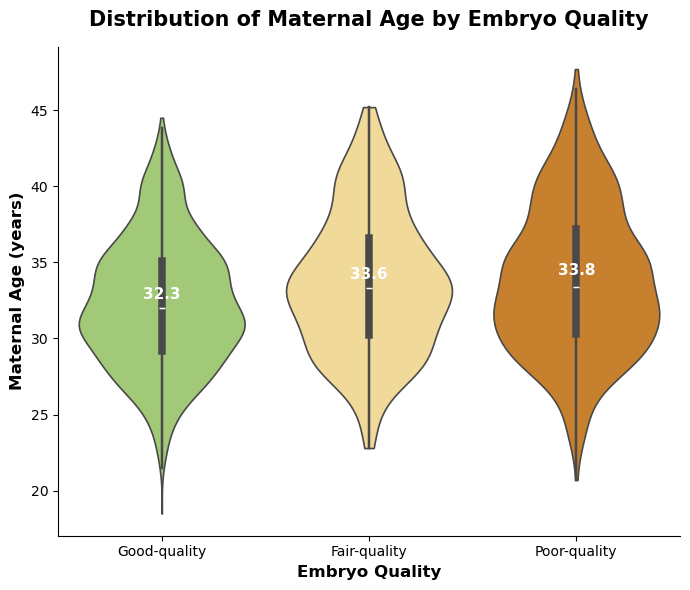

In [14]:
# ==============================
# 8️⃣ 统计不同质量的平均年龄
# ==============================
# 先恢复 fair 胚胎：用同样的规则打上标签
def classify_quality_full(grade_abc):
    exp, icm, te = grade_abc[0], grade_abc[1], grade_abc[2]
    if grade_abc in FAIR_SET:
        return "Fair-quality"
    if int(exp) >= 3 and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    return "Poor-quality"

df_full = df_filtered.copy()
df_full["GradeABC"] = df_full["移植胚胎存活细胞数1"].apply(to_abc_grade)
df_full = df_full[df_full["GradeABC"].notna()].copy()
df_full["Quality"] = df_full["GradeABC"].apply(classify_quality_full)

# 只保留有效年龄
df_full["年龄"] = pd.to_numeric(df_full["年龄"], errors="coerce")
df_full = df_full[df_full["年龄"].notna()]

# 计算平均年龄
mean_age = df_full.groupby("Quality")["年龄"].mean().round(2)

print("\n不同质量胚胎的平均母体年龄：")
for q, age in mean_age.items():
    print(f"  {q}: 平均年龄 = {age} 岁 (n={len(df_full[df_full['Quality']==q])})")


# ==============================
# 9️⃣ 小提琴图：不同质量胚胎的年龄分布
# ==============================
import seaborn as sns
import matplotlib.pyplot as plt

# 只保留三类
df_plot = df_full[df_full["Quality"].isin(["Good-quality", "Fair-quality", "Poor-quality"])].copy()
df_plot["Quality"] = pd.Categorical(
    df_plot["Quality"],
    categories=["Good-quality", "Fair-quality", "Poor-quality"],
    ordered=True
)

# 🎨 定义配色：绿色→黄色→橙色（从好到差）
palette = ["#A1D76A", "#FEE08B", "#E08214"]

plt.figure(figsize=(7, 6))
sns.violinplot(
    data=df_plot,
    x="Quality",
    y="年龄",
    inner="box",        # 在小提琴中显示箱线
    scale="width",      # 使小提琴宽度一致
    cut=0,              # 不延伸超出范围
    linewidth=1.2,
    palette=palette
)

# 均值标注（红点）
mean_ages = df_plot.groupby("Quality")["年龄"].mean()
for i, (q, m) in enumerate(mean_ages.items()):
    plt.text(i, m + 0.3, f"{m:.1f}", ha="center", color="white", fontsize=11, fontweight="bold")

plt.title("Distribution of Maternal Age by Embryo Quality", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Embryo Quality", fontsize=12, fontweight="bold")
plt.ylabel("Maternal Age (years)", fontsize=12, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

# df_full 已有
# patient_birth = pd.read_csv("PatientBirthDates.csv")
# slide_birth   = pd.read_csv("SlidePatientBirhthDates.csv")

# 1. 类型统一
df_full["女病人ID"] = pd.to_numeric(df_full["女病人ID"], errors="coerce")
patient_birth["PatientID"] = pd.to_numeric(patient_birth["PatientID"], errors="coerce")

# 2. 去重：一位患者一个 PatientIDX
patient_birth_unique = patient_birth.drop_duplicates(subset=["PatientID"])

# 3. 第一次 merge：获得 PatientIDX
df_tmp = df_full.merge(
    patient_birth_unique[["PatientID", "PatientIDX"]],
    left_on="女病人ID",
    right_on="PatientID",
    how="left"
)

# 🔥【关键修复】删除 df_tmp 中已有的 SlideID（可能是过往 merge 引入）
df_tmp = df_tmp.drop(columns=[col for col in df_tmp.columns if "SlideID" in col], errors="ignore")

# 4. slide_birth 去重（每个 PatientIDX 对应一个 slide）
slide_unique = slide_birth.drop_duplicates(subset=["PatientIDX"])

# 5. 第二次 merge：加上 SlideID
df_tmp = df_tmp.merge(
    slide_unique[["PatientIDX", "SlideID"]],
    on="PatientIDX",
    how="left"
)

# 6. 清理中间列
df_tmp = df_tmp.drop(columns=["PatientID", "PatientIDX"], errors="ignore")

# 7. 得到最终结果
df_full = df_tmp

# 8. 筛选 Fair-quality 行
df_fair = df_full[df_full["Quality"] == "Fair-quality"]

df_fair_no_nan = df_fair.dropna(subset=["SlideID"])
print(df_fair_no_nan[["女病人ID", "Quality", "年龄", "SlideID"]])

# df_fair_no_nan.to_csv("/Users/lzz/Downloads/df_fair_no_nan.csv",
#                       index=False, encoding="utf-8-sig")

NameError: name 'patient_birth' is not defined

In [17]:
import pandas as pd
import re

# =======================
# 1. 读取三个表
# =======================

df_patient = pd.read_csv("/Users/lzz/Downloads/df_fair_no_nan.csv")
df_pred = pd.read_csv("/Users/lzz/Downloads/embryo_results_2025-12-10.csv")
df_maindb = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/prediction/code/MainDB.csv")


# =======================
# 2. 第一阶段：病人表 + 预测表（按 SlideID 合并）
# =======================
df_pred["SlideID"] = df_pred["embryo_id"].str.extract(
    r"^(D\d{4}\.\d{2}\.\d{2}_S\d+_I\d+_P)"
)

merged = df_patient.merge(df_pred, on="SlideID", how="inner")


# =======================
# 3. 修复 MainDB：RowName → embryo_id 格式
# =======================
# RowName:  Dxxxx_P_10
# 目标:     Dxxxx_P_WELL10

df_maindb["embryo_id"] = df_maindb["RowName"].str.replace(
    r"_(\d+)$", r"_WELL\1", regex=True
)

df_maindb = df_maindb.rename(columns={"Quality": "MainDB_Quality"})


# =======================
# 4. 第二阶段：按完整 embryo_id 合并（关键修复）
# =======================

# 先按 embryo_id 去重（每个胚胎只保留第一条）
df_maindb_unique = df_maindb.drop_duplicates(subset=["embryo_id"])

# 一对一合并
merged = merged.merge(
    df_maindb_unique[["embryo_id", "ICM", "TE", "MainDB_Quality"]],
    on="embryo_id",
    how="left"
)

print("\n合并后前几行：")
print(merged.head())


# =======================
# 5. 按预测分类统计平均年龄
# =======================
age_stats = merged.groupby("prediction")["年龄"].mean().round(2)

print("\n📊 平均年龄统计:")
print(age_stats)

merged["Grade_ICM"] = merged["囊胚等级"].str[-2:-1]
merged["Grade_TE"]  = merged["囊胚等级"].str[-1:]

# ================================
# 2. 筛选囊胚等级与 MainDB 的 ICM/TE 匹配的行
# ================================

filtered = merged[
    (merged["Grade_ICM"] == merged["ICM"]) &
    (merged["Grade_TE"] == merged["TE"])
]

filtered.to_csv("merged_by_full_embryo_id.csv", index=False, encoding="utf-8-sig")
age_stats.to_csv("prediction_age_stats.csv", header=True)
print("\n已输出：merged_by_full_embryo_id.csv")


合并后前几行：
    女病人ID   ARTID    年龄  Bmi(新鲜周期)  移植胚胎存活细胞数1  移植胚胎存活细胞数2  移植数  妊娠结局  胎儿数  \
0  269724  249004  25.0      31.93         422         NaN    1   未妊娠    0   
1  269724  249004  25.0      31.93         422         NaN    1   未妊娠    0   
2  269724  249004  25.0      31.93         422         NaN    1   未妊娠    0   
3  269724  249004  25.0      31.93         422         NaN    1   未妊娠    0   
4  274084  232761  33.9      29.38         422         NaN    1  临床妊娠    1   

  囊胚等级  ...    年龄段 GradeABC                     SlideID  \
0  4BB  ...  25-29      4BB  D2023.06.25_S00783_I4424_P   
1  4BB  ...  25-29      4BB  D2023.06.25_S00783_I4424_P   
2  4BB  ...  25-29      4BB  D2023.06.25_S00783_I4424_P   
3  4BB  ...  25-29      4BB  D2023.06.25_S00783_I4424_P   
4  4BB  ...  30-34      4BB  D2022.11.14_S00413_I4424_P   

                           embryo_id prediction confidence focal_planes  ICM  \
0  D2023.06.25_S00783_I4424_P_WELL10       Poor    100.00%           11    B   
1  D202

In [18]:
import pandas as pd
from scipy.stats import fisher_exact

# ===============================
# Step 0 — 去除移植数为 2 的胚胎
# ===============================

# 只保留移植数 = 1
filtered = filtered[filtered["移植数"] == 1].copy()

print("筛除移植数=2后剩余行数：", len(filtered))


# ===============================
# Step 1 — 生成 embryo_base_id（去掉 WELL）
# ===============================

filtered["embryo_base_id"] = filtered["embryo_id"].str.extract(
    r"^(D\d{4}\.\d{2}\.\d{2}_S\d+_I\d+_P)"
)


# ===============================
# Step 2 — 因为移植数=1，直接每组保留一个胚胎
# ===============================

result_rows = []

for (pid, art), group in filtered.groupby(["女病人ID", "ARTID"]):

    # 移植数保证都是 1
    unique_embryos = group.drop_duplicates(subset="embryo_base_id")
    
    # 只保留 1 个胚胎（一个移植事件）
    selected = unique_embryos.head(1)
    result_rows.append(selected)

filtered_final = pd.concat(result_rows, ignore_index=True)

print("最终保留的单胚胎移植记录数：", len(filtered_final))


# ===============================
# Step 3 — 计算 Good / Poor 妊娠率
# ===============================

preg_rate = (
    filtered_final
    .groupby("prediction")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)

preg_rate["妊娠概率"] = preg_rate["临床妊娠数"] / preg_rate["总数"] * 100

print("\n===== Good / Poor 妊娠率（移植数=1）=====")
print(preg_rate)


# ===============================
# Step 4 — Two-tailed Fisher's Exact Test
# ===============================

contingency = pd.crosstab(
    filtered_final["prediction"],
    filtered_final["妊娠结局"] == "临床妊娠"
)

print("\n===== 列联表（用于 Fisher’s Test）=====")
print(contingency)

oddsratio, pvalue = fisher_exact(contingency, alternative="two-sided")

print(f"\nOdds Ratio（Good vs Poor）: {oddsratio:.4f}")
print(f"Two-tailed Fisher’s Exact Test p-value: {pvalue:.6f}")

print("\n=== 分析完成（移植数=1） ===")

筛除移植数=2后剩余行数： 569
最终保留的单胚胎移植记录数： 343

===== Good / Poor 妊娠率（移植数=1）=====
  prediction   总数  临床妊娠数       妊娠概率
0       Good  188    114  60.638298
1       Poor  155     78  50.322581

===== 列联表（用于 Fisher’s Test）=====
妊娠结局        False  True 
prediction              
Good           74    114
Poor           77     78

Odds Ratio（Good vs Poor）: 0.6576
Two-tailed Fisher’s Exact Test p-value: 0.063394

=== 分析完成（移植数=1） ===



不同质量胚胎的平均母体 BMI：
  Fair-quality: 平均 BMI = 22.17 (n=475)
  Good-quality: 平均 BMI = 22.25 (n=1610)
  Poor-quality: 平均 BMI = 22.42 (n=589)


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/3206087336.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_72456/3206087336.py:20: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


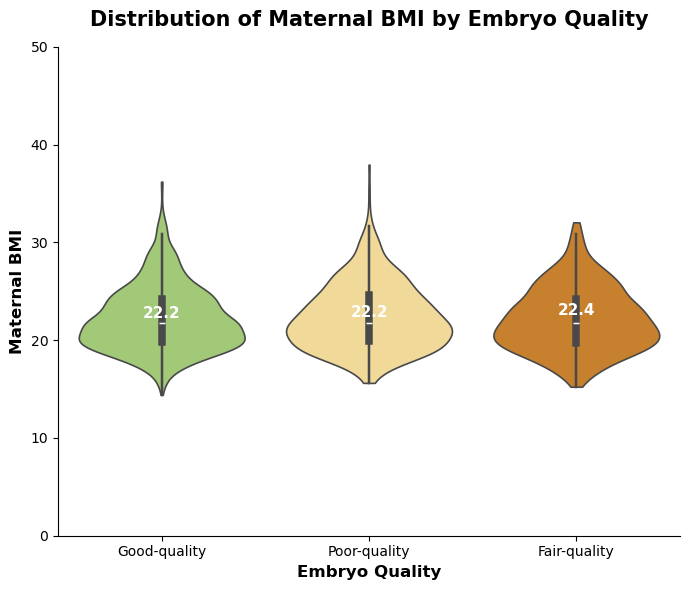

In [16]:
# ==============================
# 统计不同质量的平均 BMI
# ==============================
# 转换为数值
df_full["Bmi(新鲜周期)"] = pd.to_numeric(df_full["Bmi(新鲜周期)"], errors="coerce")
df_full = df_full[df_full["Bmi(新鲜周期)"].notna()]

# 计算平均 BMI
mean_bmi = df_full.groupby("Quality")["Bmi(新鲜周期)"].mean().round(2)

print("\n不同质量胚胎的平均母体 BMI：")
for q, bmi in mean_bmi.items():
    print(f"  {q}: 平均 BMI = {bmi} (n={len(df_full[df_full['Quality']==q])})")


# ==============================
# 小提琴图：不同质量胚胎的 BMI 分布
# ==============================
plt.figure(figsize=(7, 6))
sns.violinplot(
    data=df_full[df_full["Quality"].isin(["Good-quality", "Fair-quality", "Poor-quality"])],
    x="Quality",
    y="Bmi(新鲜周期)",
    inner="box",
    scale="width",
    cut=0,
    linewidth=1.2,
    palette=palette
)

# 均值标注
mean_bmis = df_full.groupby("Quality")["Bmi(新鲜周期)"].mean()
for i, (q, m) in enumerate(mean_bmis.items()):
    plt.text(i, m + 0.1, f"{m:.1f}", ha="center", color="white", fontsize=11, fontweight="bold")

plt.title("Distribution of Maternal BMI by Embryo Quality", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Embryo Quality", fontsize=12, fontweight="bold")
plt.ylabel("Maternal BMI", fontsize=12, fontweight="bold")

# 设置坐标轴范围
plt.ylim(0, 50)     # ← 调整这里的上下限，根据你的数据分布可改成 (16, 28) 等
# plt.xlim(-0.5, 2.5)  # 如果需要控制横轴间距，也可以取消注释这一行

sns.despine()
plt.tight_layout()
plt.show()

## Cohen’s kappa

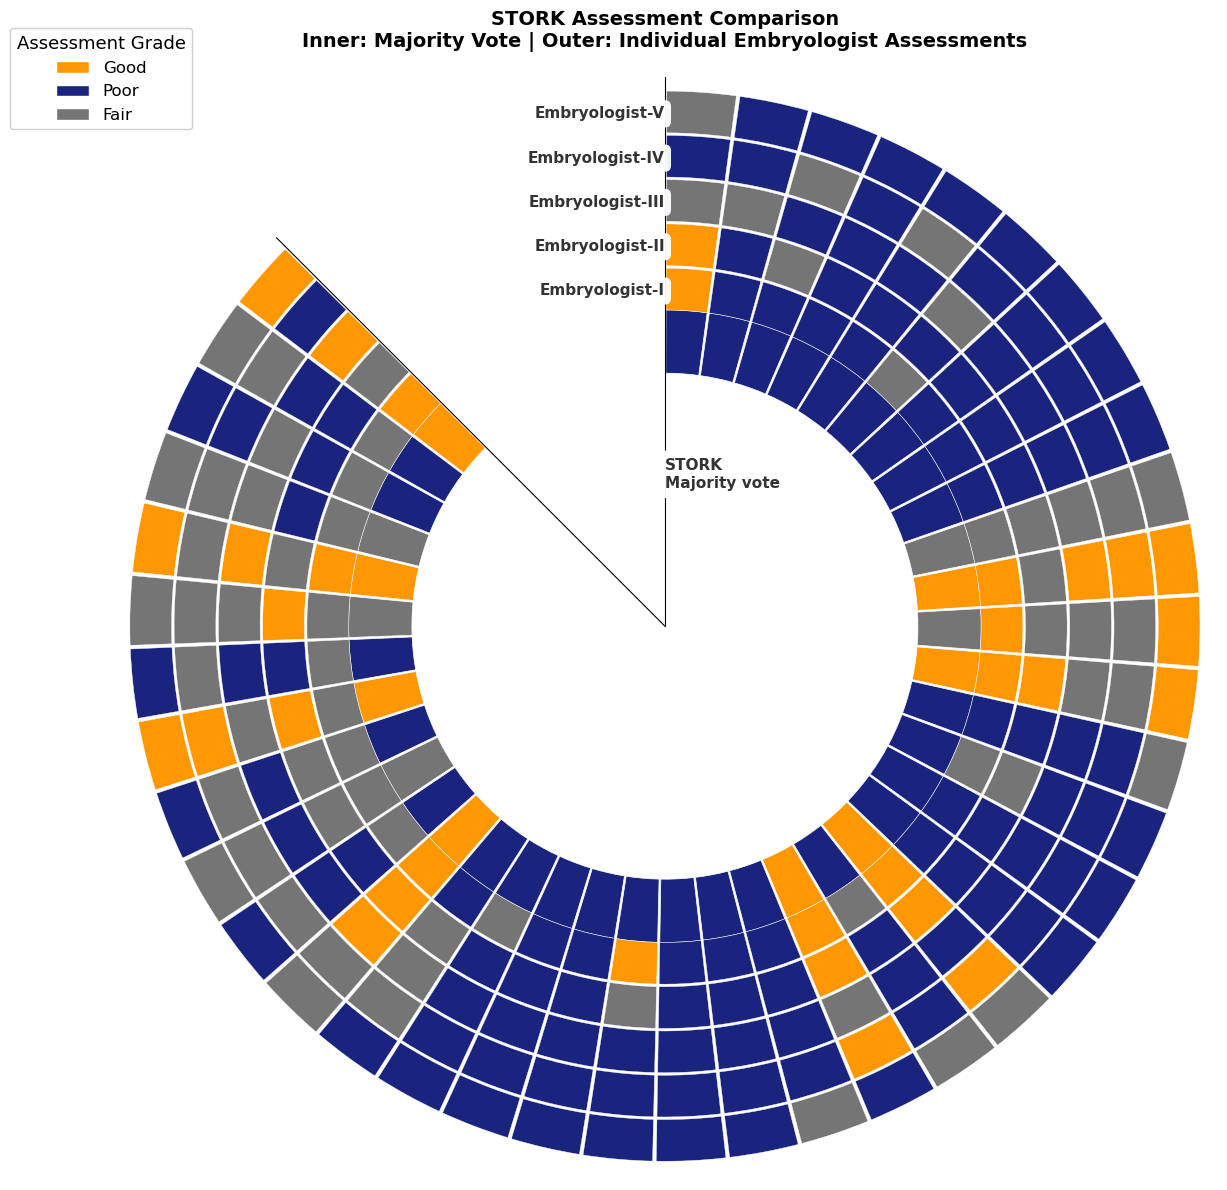

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# =========================
# 1️⃣ 读取和处理数据
# =========================
df = pd.read_csv("../../Assessment_comparison.csv", sep="\t|,|;", engine="python")
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    """按照标准分类质量"""
    if not isinstance(grade, str):
        return np.nan
    grade = grade.strip().upper()
    if "MORULA" in grade:
        return "Morula"
    if len(grade) < 3:
        return np.nan
    expansion, icm, te = grade[0], grade[1], grade[2]
    grade_3char = grade[:3]
    if grade_3char in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair"
    elif expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    else:
        return "Poor"

cols = df.columns[1:]
for col in cols:
    df[col + "_quality"] = df[col].apply(map_quality)

def majority_vote(row):
    votes = row[[c + "_quality" for c in cols]].dropna().values
    if len(votes) == 0:
        return np.nan
    vals, counts = np.unique(votes, return_counts=True)
    return vals[np.argmax(counts)]

df["MajorityVote"] = df.apply(majority_vote, axis=1)

# =========================
# 2️⃣ 颜色与映射
# =========================
color_map = {"Good": "#FF9800", "Poor": "#1A237E", "Fair": "#757575"}
expert_map = {
    "A": "Embryologist-I",
    "B": "Embryologist-II",
    "C": "Embryologist-III",
    "D": "Embryologist-IV",
    "F": "Embryologist-V",
}

# =========================
# 3️⃣ 创建圆环图（留白左上 1/8）
# =========================
fig, ax = plt.subplots(figsize=(14, 12), subplot_kw=dict(projection="polar"))

n_embryos = len(df)
angle_start = np.deg2rad(225)     # 起始角度（左下）
angle_range = np.deg2rad(315)     # 显示 7/8 圆（留白左上 1/8）
angle_per_embryo = angle_range / n_embryos

# 绘制每个胚胎的环形条
for embryo_idx, (_, row) in enumerate(df.iterrows()):
    start_angle = angle_start + embryo_idx * angle_per_embryo
    angle = start_angle + angle_per_embryo / 2
    width = angle_per_embryo * 0.95

    # 内层：多数投票
    consensus_color = color_map.get(row["MajorityVote"], "#CCCCCC")
    ax.bar(
        angle, 0.5, width=width, bottom=2.0,
        color=consensus_color, edgecolor="white", linewidth=0.5
    )

    # 外层：五位专家
    expert_order = ["A", "B", "C", "D", "E"]
    for i, code in enumerate(expert_order):
        quality_color = color_map.get(row[code + "_quality"], "#CCCCCC")
        r_inner = 2.5 + i * 0.35
        ax.bar(
            angle, 0.33, width=width, bottom=r_inner,
            color=quality_color, edgecolor="white", linewidth=0.3
        )

# =========================
# 4️⃣ 标签
# =========================
label_radii = [2.65, 3.00, 3.35, 3.70, 4.05]
label_angle = np.deg2rad(225)
for code, radius in zip(["A", "B", "C", "D", "F"], label_radii):
    ax.text(
        label_angle, radius, expert_map[code],
        ha="right", va="center", fontsize=11, fontweight="bold",
        color="#333333",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.95, edgecolor="none"),
    )

ax.text(
    label_angle, 1.2, "STORK\nMajority vote",
    ha="left", va="center", fontsize=11, fontweight="bold",
    color="#333333",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.95, edgecolor="none"),
)

# =========================
# 5️⃣ 样式设置（关键：顺时针旋转 90°）
# =========================
ax.set_theta_offset(np.deg2rad(-45))  # ⬅ 顺时针旋转 90°
ax.set_theta_direction(-1)            # 顺时针方向
ax.set_thetamin(225)
ax.set_thetamax(540)

ax.set_xticks([])
ax.set_yticks([])
ax.spines["polar"].set_visible(False)
ax.grid(False)

# 图例
legend_elems = [
    mpatches.Patch(facecolor=color_map["Good"], edgecolor="white", label="Good"),
    mpatches.Patch(facecolor=color_map["Poor"], edgecolor="white", label="Poor"),
    mpatches.Patch(facecolor=color_map["Fair"], edgecolor="white", label="Fair"),
]
ax.legend(
    handles=legend_elems,
    loc="upper left",
    bbox_to_anchor=(-0.1, 1.05),
    fontsize=12,
    title="Assessment Grade",
    title_fontsize=13,
    framealpha=0.95,
)

plt.title(
    "STORK Assessment Comparison\nInner: Majority Vote | Outer: Individual Embryologist Assessments",
    fontsize=14, fontweight="bold", pad=20,
)
plt.tight_layout()
plt.show()

/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 35745 (\N{CJK UNIFIED IDEOGRAPH-8BA1}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 22312 (\N{CJK UNIFIED IDEOGRAPH-5728}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 36825 (\N{CJK UNIFIED IDEOGRAPH-8FD9}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 20123 (\N{CJK UNIFIED IDEOGRAPH-4E9B}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 19987 (\N{CJK UNIFIED IDEOGRAP

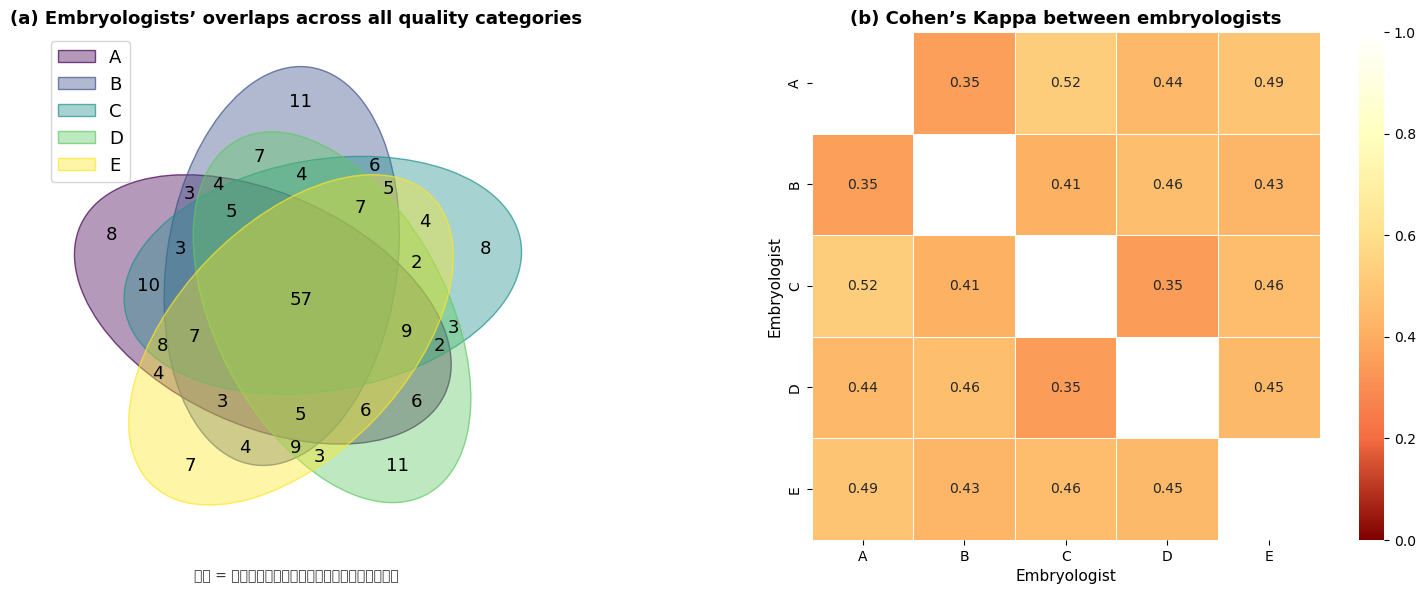

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from sklearn.metrics import cohen_kappa_score
from matplotlib.colors import LinearSegmentedColormap
from venn import venn  

# =========================
# 1️⃣ 读取并映射质量
# =========================
df = pd.read_excel(
    "/Users/lzz/Downloads/compare_table.xls"
)
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    if not isinstance(grade, str):
        return np.nan
    grade = grade.strip().upper()
    if "MORULA" in grade:
        return "Morula"
    if len(grade) < 3:
        return np.nan
    expansion, icm, te = grade[0], grade[1], grade[2]
    g3 = grade[:3]
    if g3 in {"3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"}:
        return "Fair"
    if expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    return "Poor"

experts = ["A", "B", "C", "D", "E"]
for col in experts:
    df[f"{col}_q"] = df[col].apply(map_quality)

# =========================
# 2️⃣ 五专家 Venn 图数据
# =========================
expert_sets = {
    exp: {
        f"{embryo}|{label}"
        for embryo, label in zip(df["EmbryoID"], df[f"{exp}_q"])
        if pd.notna(label)
    }
    for exp in experts
}

# =========================
# 3️⃣ 计算 Cohen’s Kappa 矩阵
# =========================
kappa_matrix = pd.DataFrame(np.eye(len(experts)), index=experts, columns=experts)
for a, b in combinations(experts, 2):
    subset = df[[f"{a}_q", f"{b}_q"]].dropna()
    kappa = np.nan if subset.empty else cohen_kappa_score(subset.iloc[:, 0], subset.iloc[:, 1])
    kappa_matrix.loc[a, b] = kappa
    kappa_matrix.loc[b, a] = kappa

# =========================
# 4️⃣ 自定义颜色映射（高一致性 = 白色）
# =========================
white_hot = LinearSegmentedColormap.from_list(
    "white_hot", ["#7f0000", "#f46d43", "#fdae61", "#fee08b", "#ffffbf", "#ffffff"]
)

# =========================
# 5️⃣ 绘制并排图像 (Supplementary Figure 1)
# =========================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- (a) Venn 图 ---
venn(expert_sets, fmt="{size}", legend_loc="upper left", ax=axes[0])
axes[0].set_title("(a) Embryologists’ overlaps across all quality categories", fontsize=13, fontweight="bold")
axes[0].annotate(
    "计数 = 在这些专家中得到完全相同质量等级的胚胎数",
    xy=(0.5, -0.08), xycoords="axes fraction",
    ha="center", fontsize=10, color="#333333"
)

# --- (b) Cohen’s Kappa 热图 ---
mask = np.eye(len(kappa_matrix), dtype=bool)  # ✅ 只遮住对角线
sns.heatmap(
    kappa_matrix.astype(float),
    annot=True,
    mask=mask,               # 只隐藏对角线上的注释
    cmap=white_hot,
    vmin=0, vmax=1,
    linewidths=0.7, linecolor="white",
    cbar=True,
    square=True,
    ax=axes[1],
    fmt=".2f"
)
axes[1].set_title("(b) Cohen’s Kappa between embryologists", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Embryologist", fontsize=11)
axes[1].set_ylabel("Embryologist", fontsize=11)

plt.tight_layout()
plt.show()

In [78]:
# =========================
# 6️⃣ 计算 STORK 与各专家的 Cohen’s kappa（仅 Good / Poor）
# =========================
df["STORK_q"] = df["STORK"].apply(lambda x: str(x).strip().capitalize() if pd.notna(x) else np.nan)

# 仅保留 Good / Poor 的行
df_filtered = df[df["STORK_q"].isin(["Good", "Poor"])].copy()

stork_kappa = {}
for exp in experts:
    subset = df_filtered[[f"{exp}_q", "STORK_q"]].dropna()
    # 同样只考虑专家的 Good / Poor
    subset = subset[subset[f"{exp}_q"].isin(["Good", "Poor"])]
    stork_kappa[exp] = np.nan if subset.empty else cohen_kappa_score(subset.iloc[:, 0], subset.iloc[:, 1])

stork_kappa = pd.Series(stork_kappa, name="STORK_vs_Expert")

# =========================
# 7️⃣ 计算五专家“投票后”结果（只保留 Good / Poor）
# =========================
def majority_vote(row):
    votes = [row[f"{exp}_q"] for exp in experts if pd.notna(row[f"{exp}_q"])]
    if not votes:
        return np.nan
    # 投票时仍计入 Fair，但稍后我们过滤掉它
    return max(set(votes), key=votes.count)

df["Vote_q"] = df.apply(majority_vote, axis=1)

# 仅保留投票结果为 Good/Poor 且 STORK 也有对应值的样本
subset_vote = df[df["Vote_q"].isin(["Good", "Poor"]) & df["STORK_q"].isin(["Good", "Poor"])][["Vote_q", "STORK_q"]]

kappa_vote = np.nan if subset_vote.empty else cohen_kappa_score(subset_vote.iloc[:, 0], subset_vote.iloc[:, 1])

# =========================
# 8️⃣ 输出 kappa
# =========================
print("📊 STORK vs 各专家的 Cohen’s kappa (仅 Good/Poor)：")
print(stork_kappa.round(3))
print("\n📊 STORK vs 投票结果的 Cohen’s kappa (仅 Good/Poor)：", round(kappa_vote, 3))

# =========================
# 9️⃣ Precision / Recall / F1 （Good 为正类）
# =========================
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

subset_vote["Vote_bin"] = subset_vote["Vote_q"].map({"Good": 1, "Poor": 0})
subset_vote["STORK_bin"] = subset_vote["STORK_q"].map({"Good": 1, "Poor": 0})

precision = precision_score(subset_vote["Vote_bin"], subset_vote["STORK_bin"], zero_division=0)
recall = recall_score(subset_vote["Vote_bin"], subset_vote["STORK_bin"], zero_division=0)
f1 = f1_score(subset_vote["Vote_bin"], subset_vote["STORK_bin"], zero_division=0)

cm = confusion_matrix(subset_vote["Vote_bin"], subset_vote["STORK_bin"])
tn, fp, fn, tp = cm.ravel()

# ✅ 统计参与分析的总胚胎数量
n_total = len(subset_vote)

# =========================
# 🔟 输出所有结果
# =========================
print("\n📈 STORK vs 投票结果分类表现（仅 Good/Poor）：")
print(f"Total embryos analyzed: {n_total}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"Confusion matrix: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

📊 STORK vs 各专家的 Cohen’s kappa (仅 Good/Poor)：
A    0.822
B    0.853
C    0.762
D    0.950
E    0.792
Name: STORK_vs_Expert, dtype: float64

📊 STORK vs 投票结果的 Cohen’s kappa (仅 Good/Poor)： 0.864

📈 STORK vs 投票结果分类表现（仅 Good/Poor）：
Total embryos analyzed: 130
Precision: 0.914
Recall:    0.889
F1-score:  0.901
Confusion matrix: TP=32, FP=3, FN=4, TN=91
